# Scaffold plank counter: everything in one Colab notebook

You only need to upload the **5 test images** when asked. Nothing else.
1. Runtime > Change runtime type > **T4 GPU** > Save.
2. Run the cells from top to bottom (Shift+Enter on each).

What it does: generates synthetic training images, trains a small YOLOv8 detector on them,
counts the planks inside the stack of each test image, draws numbered boxes, times the model,
exports Core ML / ONNX, and gives you a zip to download.

## 1. Install and settings

In [1]:
!nvidia-smi | head -15
!pip -q install ultralytics onnx

# settings
N_TRAIN = 1000      # synthetic training images
N_VAL = 150
EPOCHS = 30
IMGSZ = 512
CONF = 0.5          # detection confidence for counting (lower = more boxes)
IOU = 0.5           # overlap threshold for removing duplicate boxes
ASPECT_MAX = 6.0    # drop boxes wider than 6x their height (side faces of stacks)

Wed Nov 11 11:12:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Write the synthetic-data generator

In [2]:
%%writefile synth_data.py
import argparse
import json
from pathlib import Path

import cv2
import numpy as np


# ---------- procedural front faces -------------------------------------------------------

def plank_stack(rng, S):
    """Return (RGBA-like image, mask, boxes[(x0,y0,x1,y1)]) of a stack front, size ~S."""
    cols = int(rng.integers(1, 6))
    layers = int(rng.integers(6, 26))
    gap_c = int(rng.integers(3, 14))
    face_w = int(rng.integers(60, 130))
    thick = int(rng.integers(14, 28))
    W = cols * face_w + (cols - 1) * gap_c
    H = layers * thick
    sc = min(0.80 * S / W, 0.80 * S / H, 2.0)
    face_w, thick, gap_c = max(8, int(face_w * sc)), max(6, int(thick * sc)), max(2, int(gap_c * sc))
    W, H = cols * face_w + (cols - 1) * gap_c, layers * thick
    img = np.zeros((H, W, 3), np.float32)
    boxes = []
    base = rng.uniform(150, 215)
    holes_per = int(rng.choice([0, 1, 2, 2, 2]))
    for c in range(cols):
        x0 = c * (face_w + gap_c)
        ctone = base + rng.uniform(-18, 18)
        for l in range(layers):
            y0 = l * thick
            tone = ctone + rng.uniform(-14, 14)
            face = np.full((thick, face_w, 3), tone, np.float32)
            face += np.linspace(rng.uniform(-18, 18), rng.uniform(-18, 18), face_w)[None, :, None]
            face[:2] += 28                       # lit top edge
            face[-3:] -= rng.uniform(35, 75)     # shadow gap towards the plank below
            for k in range(holes_per):
                hx = int(face_w * (0.5 if holes_per == 1 else (0.28, 0.72)[k]) + rng.integers(-3, 4))
                cv2.circle(face, (hx, thick // 2), max(1, int(thick * rng.uniform(0.09, 0.15))), (25, 25, 25), -1, cv2.LINE_AA)
            img[y0:y0 + thick, x0:x0 + face_w] = face
            boxes.append((x0, y0, x0 + face_w, y0 + thick))
    img += rng.normal(0, 3, img.shape)
    mask = np.zeros((H, W), np.uint8)
    for c in range(cols):
        mask[:, c * (face_w + gap_c): c * (face_w + gap_c) + face_w] = 255
    return np.clip(img, 0, 255).astype(np.uint8), mask, boxes


def tube_bundle(rng, S):
    """Hex lattice of tube ends (dark bore, bright rim)."""
    rows = int(rng.integers(4, 11))
    cols = int(rng.integers(5, 13))
    r = int(rng.integers(8, 20))
    pitch = 2 * r + int(rng.integers(0, 3))
    W = cols * pitch + pitch // 2
    H = int(rows * pitch * 0.866) + pitch
    sc = min(0.9 * S / W, 0.9 * S / H, 2.0)
    r, pitch = max(4, int(r * sc)), max(9, int(pitch * sc))
    W, H = cols * pitch + pitch // 2, int(rows * pitch * 0.866) + pitch
    img = np.full((H, W, 3), rng.uniform(70, 150), np.float32)
    mask = np.zeros((H, W), np.uint8)
    boxes = []
    for i in range(rows):
        for j in range(cols):
            cx = int(j * pitch + pitch / 2 + (pitch / 2 if i % 2 else 0))
            cy = int(i * pitch * 0.866 + pitch / 2)
            if cx + r >= W or cy + r >= H:
                continue
            rim = rng.uniform(150, 230)
            cv2.circle(img, (cx, cy), r, (rim,) * 3, -1, cv2.LINE_AA)
            cv2.circle(img, (cx, cy), int(r * rng.uniform(0.62, 0.8)), (rng.uniform(15, 60),) * 3, -1, cv2.LINE_AA)
            cv2.circle(mask, (cx, cy), r + 2, 255, -1)
            boxes.append((cx - r, cy - r, cx + r, cy + r))
    img += rng.normal(0, 3, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8), mask, boxes


# ---------- scene composition -------------------------------------------------------------

def background(rng, S):
    c0, c1 = rng.uniform(40, 190, 3), rng.uniform(40, 190, 3)
    t = np.linspace(0, 1, S)[:, None, None]
    bg = (c0 * (1 - t) + c1 * t) * np.ones((S, S, 3))
    for _ in range(int(rng.integers(0, 6))):     # shelves / pillars / floor patches
        x, y = rng.integers(0, S, 2); w, h = rng.integers(20, S // 2, 2)
        cv2.rectangle(bg, (int(x), int(y)), (int(x + w), int(y + h)), tuple(float(v) for v in rng.uniform(30, 220, 3)), -1)
    bg = cv2.GaussianBlur(bg.astype(np.float32), (0, 0), rng.uniform(1, 6))
    return bg + rng.normal(0, 4, bg.shape)


def compose(rng, S, kind):
    img, mask, boxes = (plank_stack if kind == 0 else tube_bundle)(rng, S)
    H, W = img.shape[:2]
    src = np.float32([[0, 0], [W, 0], [W, H], [0, H]])
    j = lambda a: rng.uniform(-a, a)
    sh, sw = 0.07 * H, 0.07 * W
    dst = src + np.float32([[j(sw), j(sh)], [j(sw), j(sh)], [j(sw), j(sh)], [j(sw), j(sh)]])
    dst += np.float32([(S - W) / 2 + j(S * 0.06), (S - H) / 2 + j(S * 0.06)])
    M = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(img, M, (S, S), flags=cv2.INTER_LINEAR)
    wmask = cv2.warpPerspective(mask, M, (S, S), flags=cv2.INTER_NEAREST) > 0
    out = background(rng, S)
    out[wmask] = warped[wmask]
    pts = np.float32([[[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]] for b in boxes]).reshape(-1, 1, 2)
    wp = cv2.perspectiveTransform(pts, M).reshape(-1, 4, 2)
    lab = []
    for q in wp:
        x0, y0 = q.min(0); x1, y1 = q.max(0)
        x0, y0, x1, y1 = max(0, x0), max(0, y0), min(S, x1), min(S, y1)
        if x1 - x0 > 4 and y1 - y0 > 4:
            lab.append((kind, (x0 + x1) / 2 / S, (y0 + y1) / 2 / S, (x1 - x0) / S, (y1 - y0) / S))
    # photometric degradation: exposure, glare, blur, JPEG
    out = out * rng.uniform(0.6, 1.25) + rng.uniform(-20, 20)
    gl = np.zeros((S, S), np.float32)
    cv2.circle(gl, (int(rng.integers(0, S)), int(rng.integers(0, S))), int(rng.integers(S // 8, S // 3)), 1.0, -1)
    out += cv2.GaussianBlur(gl, (0, 0), S / 12)[..., None] * rng.uniform(0, 70)
    out = cv2.GaussianBlur(np.clip(out, 0, 255).astype(np.uint8), (0, 0), rng.uniform(0.3, 1.6))
    q = int(rng.integers(35, 90))
    out = cv2.imdecode(cv2.imencode(".jpg", out, [cv2.IMWRITE_JPEG_QUALITY, q])[1], 1)
    return out, lab


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="data/synthetic")
    ap.add_argument("--train", type=int, default=300)
    ap.add_argument("--val", type=int, default=60)
    ap.add_argument("--size", type=int, default=640)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--tube_frac", type=float, default=0.25)
    a = ap.parse_args()
    rng = np.random.default_rng(a.seed)
    root = Path(a.out)
    counts = {}
    for split, n in (("train", a.train), ("val", a.val)):
        (root / "images" / split).mkdir(parents=True, exist_ok=True)
        (root / "labels" / split).mkdir(parents=True, exist_ok=True)
        for i in range(n):
            kind = 1 if rng.random() < a.tube_frac else 0
            img, lab = compose(rng, a.size, kind)
            name = f"{split}_{i:04d}"
            cv2.imwrite(str(root / "images" / split / f"{name}.jpg"), img)
            (root / "labels" / split / f"{name}.txt").write_text(
                "\n".join(f"{k} {x:.5f} {y:.5f} {w:.5f} {h:.5f}" for k, x, y, w, h in lab))
            counts[name] = {"class": "tube_end" if kind else "plank_end", "count": len(lab)}
    (root / "counts.json").write_text(json.dumps(counts, indent=1))
    (root / "dataset.yaml").write_text(
        f"path: {root.resolve()}\ntrain: images/train\nval: images/val\nnames:\n  0: plank_end\n  1: tube_end\n")
    print("wrote", len(counts), "images to", root)


if __name__ == "__main__":
    main()

Writing synth_data.py


## 3. Generate synthetic training images (planks and tube bundles)

In [3]:
!python synth_data.py --out data/synthetic --train {N_TRAIN} --val {N_VAL} --size {IMGSZ} --seed 1
!ls data/synthetic

wrote 1150 images to data/synthetic
counts.json  dataset.yaml  images  labels


## 4. Train the detector on the synthetic data (about 5 to 10 minutes on a T4)

In [4]:
!yolo detect train data=data/synthetic/dataset.yaml model=yolov8n.pt imgsz={IMGSZ} epochs={EPOCHS} batch=32 project=runs name=synth exist_ok=True plots=False

import glob, os
cands = glob.glob("**/synth/weights/best.pt", recursive=True)
WEIGHTS = max(cands, key=os.path.getmtime)
print("weights:", WEIGHTS)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/synthetic/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

## 5. Upload the 5 test images (select all 5 at once)

In [5]:
from google.colab import files
import shutil

os.makedirs("test", exist_ok=True)
up = files.upload()
for n in up:
    shutil.move(n, os.path.join("test", n))
print(sorted(os.listdir("test")))

Saving 5.jpg to 5.jpg
Saving 4.jpg to 4.jpg
Saving 3.jpeg to 3.jpeg
Saving 2.jpeg to 2.jpeg
Saving 1.jpeg to 1.jpeg
['1.jpeg', '2.jpeg', '3.jpeg', '4.jpg', '5.jpg']


## 6. Count the planks inside each stack

Each test image is recognised automatically and gets the stack box (ROI) that selects the stack to count,
like the box a user drags in the reference app. If an image is not recognised, the whole image is used;
you can then set its box yourself in `MANUAL_ROI` (pixels: x0, y0, x1, y1, key = file name).

`CORRECT` is optional: put the true counts by label, e.g. `{"Image 2": 74}`, to get an error column.

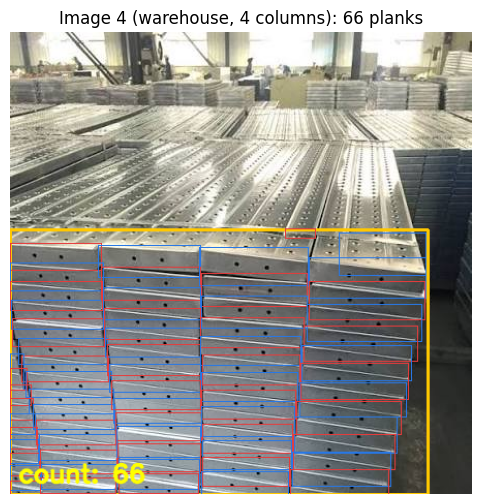

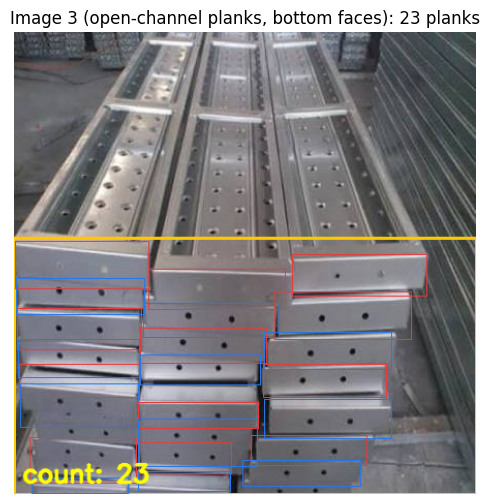

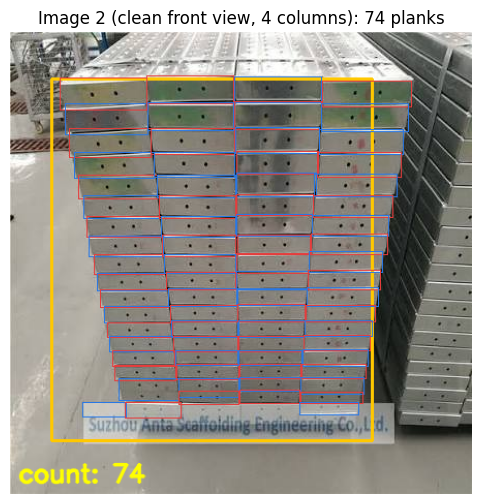

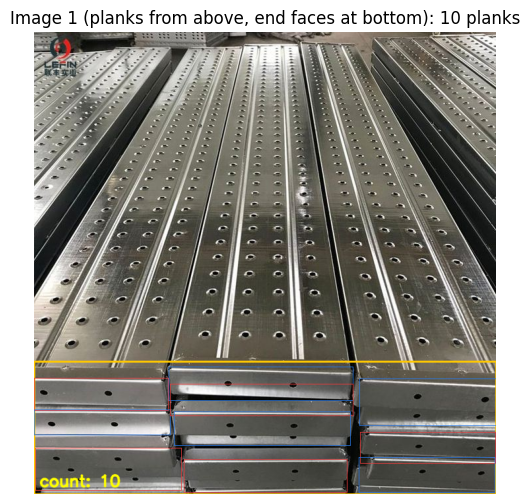

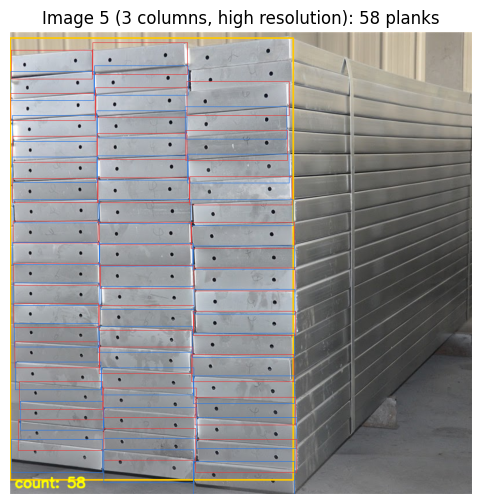

image                                               count   raw      ms
Image 4 (warehouse, 4 columns)                         66    96    31.1
Image 3 (open-channel planks, bottom faces)            23    44    15.9
Image 2 (clean front view, 4 columns)                  74   104    13.4
Image 1 (planks from above, end faces at bottom)       10    28    14.1
Image 5 (3 columns, high resolution)                   58    89    14.3


In [6]:
import json, time, csv
import numpy as np, cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

REFS = json.loads('''[{"label": "Image 1 (planks from above, end faces at bottom)", "roi": [0.0, 0.714, 1.0, 1.0], "thumb": [120.0, 69.0, 42.0, 58.0, 78.0, 115.0, 135.0, 115.0, 135.0, 95.0, 105.0, 128.0, 143.0, 149.0, 129.0, 135.0, 138.0, 117.0, 120.0, 105.0, 115.0, 141.0, 169.0, 194.0, 147.0, 122.0, 162.0, 197.0, 185.0, 191.0, 150.0, 113.0, 182.0, 185.0, 176.0, 213.0, 226.0, 185.0, 129.0, 130.0, 124.0, 98.0, 86.0, 101.0, 97.0, 115.0, 156.0, 176.0, 157.0, 138.0, 159.0, 190.0, 186.0, 166.0, 77.0, 181.0, 166.0, 159.0, 154.0, 171.0, 175.0, 154.0, 93.0, 130.0, 129.0, 93.0, 63.0, 84.0, 112.0, 117.0, 151.0, 153.0, 164.0, 142.0, 125.0, 147.0, 148.0, 69.0, 128.0, 164.0, 133.0, 138.0, 131.0, 150.0, 142.0, 137.0, 85.0, 132.0, 113.0, 124.0, 70.0, 48.0, 88.0, 132.0, 138.0, 150.0, 162.0, 146.0, 113.0, 119.0, 78.0, 61.0, 138.0, 133.0, 132.0, 122.0, 128.0, 140.0, 131.0, 133.0, 83.0, 131.0, 109.0, 127.0, 104.0, 35.0, 47.0, 99.0, 131.0, 133.0, 165.0, 143.0, 126.0, 84.0, 39.0, 112.0, 133.0, 123.0, 133.0, 118.0, 122.0, 130.0, 122.0, 132.0, 79.0, 115.0, 127.0, 119.0, 124.0, 69.0, 35.0, 48.0, 108.0, 124.0, 166.0, 152.0, 113.0, 39.0, 76.0, 127.0, 127.0, 120.0, 126.0, 113.0, 118.0, 128.0, 115.0, 132.0, 78.0, 104.0, 134.0, 110.0, 127.0, 110.0, 33.0, 39.0, 52.0, 109.0, 176.0, 156.0, 50.0, 45.0, 119.0, 131.0, 120.0, 128.0, 116.0, 112.0, 125.0, 120.0, 113.0, 139.0, 87.0, 110.0, 136.0, 112.0, 119.0, 114.0, 77.0, 28.0, 43.0, 57.0, 196.0, 85.0, 33.0, 94.0, 122.0, 126.0, 118.0, 135.0, 110.0, 114.0, 132.0, 116.0, 116.0, 156.0, 110.0, 99.0, 125.0, 115.0, 113.0, 122.0, 118.0, 39.0, 32.0, 50.0, 143.0, 39.0, 70.0, 108.0, 123.0, 97.0, 103.0, 120.0, 91.0, 88.0, 122.0, 87.0, 87.0, 124.0, 81.0, 80.0, 90.0, 105.0, 92.0, 113.0, 106.0, 86.0, 26.0, 36.0, 43.0, 41.0, 132.0, 111.0, 90.0, 73.0, 119.0, 80.0, 82.0, 73.0, 117.0, 74.0, 72.0, 108.0, 73.0, 68.0, 71.0, 106.0, 72.0, 79.0, 106.0, 84.0, 46.0, 29.0, 33.0, 124.0, 138.0, 135.0, 82.0, 82.0, 122.0, 83.0, 89.0, 79.0, 128.0, 77.0, 76.0, 122.0, 74.0, 71.0, 75.0, 120.0, 83.0, 74.0, 114.0, 87.0, 86.0, 28.0, 69.0, 200.0, 139.0, 134.0, 87.0, 102.0, 112.0, 80.0, 86.0, 76.0, 138.0, 72.0, 68.0, 135.0, 70.0, 69.0, 71.0, 104.0, 110.0, 81.0, 91.0, 120.0, 96.0, 63.0, 192.0, 169.0, 166.0, 125.0, 89.0, 129.0, 87.0, 86.0, 81.0, 89.0, 133.0, 69.0, 72.0, 146.0, 66.0, 58.0, 77.0, 77.0, 147.0, 79.0, 79.0, 134.0, 93.0, 111.0, 198.0, 151.0, 172.0, 124.0, 99.0, 135.0, 97.0, 100.0, 90.0, 112.0, 124.0, 79.0, 78.0, 155.0, 73.0, 74.0, 76.0, 83.0, 153.0, 83.0, 81.0, 110.0, 125.0, 101.0, 158.0, 156.0, 152.0, 127.0, 125.0, 121.0, 104.0, 99.0, 97.0, 127.0, 121.0, 89.0, 88.0, 159.0, 77.0, 87.0, 76.0, 89.0, 125.0, 116.0, 90.0, 97.0, 138.0, 99.0, 135.0, 158.0, 143.0, 123.0, 135.0, 113.0, 106.0, 96.0, 90.0, 128.0, 102.0, 87.0, 82.0, 148.0, 80.0, 80.0, 73.0, 88.0, 101.0, 138.0, 98.0, 104.0, 130.0, 123.0, 114.0, 126.0, 118.0, 109.0, 111.0, 101.0, 97.0, 115.0, 112.0, 108.0, 104.0, 99.0, 94.0, 93.0, 92.0, 93.0, 78.0, 93.0, 87.0, 118.0, 100.0, 102.0, 120.0, 126.0, 120.0, 125.0, 126.0, 122.0, 131.0, 133.0, 115.0, 112.0, 159.0, 154.0, 143.0, 140.0, 128.0, 117.0, 112.0, 100.0, 78.0, 94.0, 98.0, 97.0, 98.0, 101.0, 103.0, 108.0, 134.0, 133.0, 132.0, 132.0, 134.0, 136.0, 132.0, 101.0, 116.0, 110.0, 102.0, 97.0, 93.0, 91.0, 97.0, 100.0, 66.0, 76.0, 78.0, 74.0, 77.0, 80.0, 81.0, 79.0, 159.0, 164.0, 166.0, 167.0, 163.0, 179.0, 179.0, 100.0, 104.0, 97.0, 83.0, 83.0, 79.0, 70.0, 75.0, 76.0, 50.0, 109.0, 136.0, 139.0, 143.0, 145.0, 152.0, 148.0, 132.0, 130.0, 132.0, 133.0, 132.0, 138.0, 143.0, 53.0, 136.0, 137.0, 120.0, 113.0, 104.0, 93.0, 92.0, 93.0, 29.0, 70.0, 75.0, 75.0, 79.0, 83.0, 83.0, 85.0, 90.0, 80.0, 86.0, 88.0, 85.0, 91.0, 93.0, 82.0, 110.0, 105.0, 97.0, 92.0, 87.0, 81.0, 80.0, 81.0, 47.0, 71.0, 85.0, 86.0, 84.0, 86.0, 87.0, 88.0, 98.0, 130.0, 133.0, 139.0, 137.0, 137.0, 150.0, 139.0, 99.0, 101.0, 96.0, 91.0, 85.0, 81.0, 80.0, 81.0, 51.0, 83.0, 80.0, 80.0, 78.0, 75.0, 73.0, 74.0]}, {"label": "Image 2 (clean front view, 4 columns)", "roi": [0.0895, 0.1007, 0.783, 0.884], "thumb": [158.0, 142.0, 138.0, 135.0, 126.0, 130.0, 200.0, 209.0, 202.0, 221.0, 214.0, 202.0, 232.0, 237.0, 234.0, 215.0, 210.0, 226.0, 187.0, 112.0, 112.0, 112.0, 166.0, 199.0, 146.0, 105.0, 122.0, 140.0, 180.0, 192.0, 174.0, 199.0, 190.0, 219.0, 208.0, 195.0, 229.0, 239.0, 235.0, 215.0, 196.0, 206.0, 218.0, 188.0, 94.0, 94.0, 104.0, 121.0, 126.0, 100.0, 121.0, 187.0, 190.0, 180.0, 173.0, 156.0, 143.0, 148.0, 140.0, 133.0, 138.0, 128.0, 134.0, 147.0, 167.0, 180.0, 184.0, 177.0, 146.0, 78.0, 89.0, 99.0, 116.0, 103.0, 108.0, 127.0, 129.0, 128.0, 132.0, 110.0, 107.0, 102.0, 101.0, 97.0, 106.0, 93.0, 100.0, 119.0, 122.0, 115.0, 103.0, 102.0, 99.0, 70.0, 80.0, 81.0, 154.0, 130.0, 100.0, 89.0, 82.0, 86.0, 116.0, 103.0, 100.0, 98.0, 104.0, 98.0, 80.0, 75.0, 84.0, 113.0, 112.0, 108.0, 101.0, 102.0, 97.0, 67.0, 68.0, 89.0, 137.0, 103.0, 90.0, 116.0, 113.0, 115.0, 120.0, 124.0, 127.0, 127.0, 120.0, 111.0, 98.0, 103.0, 97.0, 131.0, 127.0, 131.0, 126.0, 132.0, 93.0, 60.0, 61.0, 99.0, 189.0, 167.0, 158.0, 129.0, 114.0, 120.0, 129.0, 121.0, 130.0, 124.0, 121.0, 110.0, 108.0, 106.0, 110.0, 134.0, 128.0, 131.0, 130.0, 132.0, 84.0, 58.0, 58.0, 113.0, 193.0, 178.0, 173.0, 144.0, 117.0, 119.0, 121.0, 124.0, 129.0, 127.0, 124.0, 107.0, 95.0, 100.0, 101.0, 123.0, 128.0, 125.0, 127.0, 131.0, 57.0, 60.0, 63.0, 114.0, 178.0, 174.0, 175.0, 164.0, 124.0, 119.0, 118.0, 122.0, 130.0, 131.0, 124.0, 116.0, 110.0, 111.0, 116.0, 131.0, 137.0, 133.0, 135.0, 134.0, 44.0, 47.0, 79.0, 134.0, 165.0, 173.0, 178.0, 175.0, 132.0, 132.0, 133.0, 129.0, 132.0, 129.0, 124.0, 118.0, 113.0, 107.0, 116.0, 126.0, 134.0, 128.0, 129.0, 112.0, 40.0, 40.0, 102.0, 128.0, 171.0, 175.0, 181.0, 177.0, 137.0, 131.0, 132.0, 127.0, 140.0, 134.0, 131.0, 124.0, 130.0, 123.0, 135.0, 130.0, 139.0, 134.0, 132.0, 100.0, 37.0, 44.0, 108.0, 130.0, 170.0, 176.0, 177.0, 177.0, 143.0, 129.0, 129.0, 131.0, 136.0, 135.0, 131.0, 124.0, 134.0, 131.0, 137.0, 134.0, 133.0, 128.0, 131.0, 79.0, 36.0, 49.0, 133.0, 129.0, 171.0, 175.0, 173.0, 177.0, 154.0, 130.0, 131.0, 137.0, 126.0, 131.0, 130.0, 124.0, 130.0, 127.0, 129.0, 131.0, 134.0, 135.0, 141.0, 62.0, 37.0, 69.0, 128.0, 128.0, 174.0, 169.0, 171.0, 174.0, 161.0, 131.0, 131.0, 136.0, 130.0, 134.0, 133.0, 129.0, 134.0, 130.0, 133.0, 133.0, 137.0, 135.0, 139.0, 45.0, 35.0, 92.0, 135.0, 129.0, 174.0, 173.0, 174.0, 175.0, 173.0, 136.0, 134.0, 134.0, 131.0, 132.0, 130.0, 126.0, 131.0, 130.0, 132.0, 132.0, 136.0, 131.0, 130.0, 32.0, 36.0, 115.0, 126.0, 125.0, 175.0, 174.0, 173.0, 177.0, 175.0, 134.0, 131.0, 130.0, 130.0, 136.0, 133.0, 127.0, 132.0, 130.0, 135.0, 130.0, 134.0, 132.0, 109.0, 33.0, 43.0, 127.0, 124.0, 124.0, 173.0, 175.0, 175.0, 178.0, 169.0, 140.0, 130.0, 128.0, 125.0, 122.0, 121.0, 118.0, 116.0, 114.0, 116.0, 127.0, 133.0, 130.0, 98.0, 34.0, 59.0, 118.0, 116.0, 117.0, 174.0, 183.0, 174.0, 173.0, 162.0, 144.0, 128.0, 127.0, 121.0, 123.0, 120.0, 117.0, 115.0, 112.0, 117.0, 116.0, 125.0, 123.0, 86.0, 37.0, 69.0, 126.0, 126.0, 128.0, 180.0, 188.0, 172.0, 167.0, 161.0, 149.0, 120.0, 118.0, 115.0, 117.0, 114.0, 106.0, 108.0, 108.0, 114.0, 111.0, 121.0, 115.0, 73.0, 41.0, 82.0, 115.0, 114.0, 115.0, 192.0, 178.0, 173.0, 167.0, 189.0, 187.0, 168.0, 163.0, 157.0, 152.0, 150.0, 148.0, 147.0, 148.0, 150.0, 153.0, 157.0, 157.0, 127.0, 107.0, 96.0, 115.0, 116.0, 115.0, 190.0, 173.0, 172.0, 170.0, 187.0, 183.0, 167.0, 131.0, 131.0, 124.0, 125.0, 125.0, 123.0, 123.0, 123.0, 128.0, 127.0, 137.0, 143.0, 135.0, 57.0, 56.0, 59.0, 55.0, 188.0, 176.0, 168.0, 166.0, 180.0, 180.0, 173.0, 150.0, 145.0, 143.0, 142.0, 141.0, 141.0, 141.0, 141.0, 142.0, 143.0, 148.0, 148.0, 146.0, 112.0, 106.0, 107.0, 108.0, 181.0, 171.0, 163.0, 161.0, 162.0, 164.0, 162.0, 145.0, 142.0, 139.0, 136.0, 136.0, 134.0, 132.0, 133.0, 135.0, 137.0, 142.0, 137.0, 137.0, 138.0, 133.0, 132.0, 133.0, 173.0, 167.0, 161.0, 161.0, 162.0, 165.0, 166.0, 151.0, 146.0, 143.0, 140.0, 138.0, 136.0, 137.0, 137.0, 138.0, 141.0, 149.0, 145.0, 143.0, 145.0, 142.0, 139.0, 139.0]}, {"label": "Image 3 (open-channel planks, bottom faces)", "roi": [0.0, 0.447, 1.0, 1.0], "thumb": [66.0, 71.0, 84.0, 72.0, 84.0, 96.0, 115.0, 147.0, 185.0, 142.0, 153.0, 179.0, 149.0, 172.0, 177.0, 134.0, 118.0, 102.0, 66.0, 80.0, 77.0, 73.0, 81.0, 74.0, 64.0, 77.0, 80.0, 75.0, 83.0, 94.0, 111.0, 134.0, 162.0, 133.0, 126.0, 150.0, 128.0, 146.0, 146.0, 111.0, 110.0, 92.0, 57.0, 76.0, 77.0, 73.0, 71.0, 81.0, 86.0, 90.0, 91.0, 92.0, 92.0, 118.0, 103.0, 183.0, 162.0, 124.0, 134.0, 166.0, 123.0, 141.0, 157.0, 132.0, 106.0, 101.0, 78.0, 78.0, 69.0, 75.0, 70.0, 68.0, 102.0, 105.0, 107.0, 106.0, 121.0, 152.0, 155.0, 180.0, 146.0, 115.0, 130.0, 139.0, 114.0, 133.0, 137.0, 135.0, 108.0, 116.0, 82.0, 85.0, 78.0, 72.0, 78.0, 67.0, 103.0, 108.0, 103.0, 100.0, 131.0, 106.0, 182.0, 172.0, 123.0, 137.0, 156.0, 162.0, 144.0, 138.0, 155.0, 157.0, 133.0, 117.0, 93.0, 88.0, 84.0, 73.0, 70.0, 77.0, 101.0, 95.0, 84.0, 129.0, 96.0, 132.0, 161.0, 133.0, 118.0, 108.0, 130.0, 131.0, 107.0, 123.0, 130.0, 129.0, 116.0, 85.0, 117.0, 88.0, 79.0, 72.0, 72.0, 72.0, 96.0, 85.0, 109.0, 129.0, 92.0, 197.0, 171.0, 139.0, 116.0, 103.0, 150.0, 152.0, 113.0, 118.0, 138.0, 147.0, 138.0, 87.0, 114.0, 98.0, 87.0, 76.0, 80.0, 70.0, 84.0, 89.0, 140.0, 85.0, 145.0, 179.0, 149.0, 127.0, 113.0, 100.0, 132.0, 136.0, 116.0, 111.0, 122.0, 129.0, 120.0, 104.0, 87.0, 116.0, 84.0, 81.0, 81.0, 76.0, 68.0, 127.0, 108.0, 87.0, 186.0, 167.0, 130.0, 117.0, 117.0, 105.0, 126.0, 126.0, 111.0, 106.0, 114.0, 126.0, 120.0, 120.0, 75.0, 122.0, 83.0, 79.0, 74.0, 79.0, 98.0, 137.0, 80.0, 131.0, 180.0, 154.0, 121.0, 106.0, 116.0, 111.0, 125.0, 123.0, 108.0, 107.0, 114.0, 122.0, 122.0, 119.0, 90.0, 94.0, 109.0, 73.0, 78.0, 76.0, 155.0, 151.0, 133.0, 173.0, 171.0, 149.0, 123.0, 112.0, 106.0, 117.0, 126.0, 125.0, 115.0, 102.0, 121.0, 121.0, 119.0, 119.0, 109.0, 77.0, 131.0, 82.0, 77.0, 77.0, 137.0, 146.0, 153.0, 160.0, 163.0, 163.0, 158.0, 118.0, 116.0, 130.0, 131.0, 128.0, 120.0, 106.0, 131.0, 135.0, 138.0, 141.0, 144.0, 148.0, 152.0, 106.0, 77.0, 78.0, 119.0, 124.0, 128.0, 130.0, 138.0, 136.0, 132.0, 131.0, 142.0, 134.0, 127.0, 123.0, 122.0, 124.0, 131.0, 135.0, 133.0, 141.0, 142.0, 143.0, 144.0, 100.0, 79.0, 80.0, 119.0, 135.0, 124.0, 132.0, 126.0, 134.0, 130.0, 127.0, 127.0, 118.0, 107.0, 103.0, 107.0, 106.0, 125.0, 134.0, 141.0, 152.0, 163.0, 178.0, 143.0, 82.0, 71.0, 86.0, 131.0, 132.0, 133.0, 134.0, 139.0, 143.0, 123.0, 134.0, 127.0, 112.0, 111.0, 103.0, 111.0, 114.0, 128.0, 131.0, 130.0, 133.0, 122.0, 131.0, 103.0, 84.0, 80.0, 83.0, 112.0, 123.0, 116.0, 122.0, 119.0, 133.0, 130.0, 134.0, 129.0, 119.0, 113.0, 107.0, 109.0, 108.0, 129.0, 130.0, 130.0, 130.0, 134.0, 132.0, 81.0, 70.0, 74.0, 68.0, 109.0, 134.0, 133.0, 144.0, 138.0, 140.0, 128.0, 137.0, 124.0, 122.0, 108.0, 109.0, 109.0, 110.0, 120.0, 113.0, 123.0, 116.0, 124.0, 119.0, 81.0, 63.0, 73.0, 73.0, 114.0, 142.0, 146.0, 150.0, 146.0, 153.0, 154.0, 187.0, 167.0, 163.0, 145.0, 147.0, 104.0, 110.0, 120.0, 129.0, 131.0, 131.0, 133.0, 117.0, 90.0, 63.0, 72.0, 76.0, 128.0, 151.0, 163.0, 177.0, 185.0, 194.0, 148.0, 154.0, 142.0, 134.0, 126.0, 121.0, 90.0, 121.0, 133.0, 135.0, 131.0, 127.0, 139.0, 115.0, 96.0, 73.0, 64.0, 69.0, 89.0, 108.0, 105.0, 112.0, 111.0, 120.0, 127.0, 147.0, 139.0, 136.0, 121.0, 119.0, 87.0, 105.0, 145.0, 151.0, 151.0, 154.0, 158.0, 115.0, 79.0, 72.0, 56.0, 66.0, 74.0, 112.0, 108.0, 111.0, 110.0, 113.0, 114.0, 122.0, 116.0, 112.0, 101.0, 100.0, 73.0, 79.0, 99.0, 97.0, 107.0, 108.0, 114.0, 108.0, 110.0, 98.0, 83.0, 73.0, 95.0, 113.0, 114.0, 124.0, 124.0, 125.0, 107.0, 121.0, 114.0, 111.0, 101.0, 98.0, 78.0, 103.0, 101.0, 112.0, 111.0, 117.0, 115.0, 117.0, 115.0, 115.0, 97.0, 78.0, 122.0, 112.0, 113.0, 122.0, 120.0, 124.0, 106.0, 125.0, 122.0, 118.0, 107.0, 92.0, 91.0, 96.0, 94.0, 103.0, 104.0, 106.0, 116.0, 122.0, 115.0, 113.0, 101.0, 78.0, 120.0, 129.0, 125.0, 135.0, 150.0, 157.0, 148.0, 164.0, 159.0, 150.0, 134.0, 65.0, 97.0, 93.0, 97.0, 98.0, 103.0, 110.0, 125.0, 126.0, 118.0, 118.0, 106.0, 92.0]}, {"label": "Image 4 (warehouse, 4 columns)", "roi": [0.0, 0.428, 0.905, 1.0], "thumb": [150.0, 212.0, 249.0, 208.0, 240.0, 152.0, 87.0, 146.0, 247.0, 239.0, 206.0, 163.0, 229.0, 254.0, 255.0, 240.0, 184.0, 179.0, 212.0, 254.0, 251.0, 213.0, 134.0, 134.0, 156.0, 186.0, 218.0, 202.0, 190.0, 183.0, 90.0, 123.0, 217.0, 241.0, 203.0, 188.0, 221.0, 244.0, 238.0, 231.0, 190.0, 187.0, 163.0, 228.0, 239.0, 209.0, 169.0, 201.0, 158.0, 138.0, 151.0, 149.0, 174.0, 135.0, 108.0, 131.0, 150.0, 195.0, 166.0, 174.0, 153.0, 167.0, 167.0, 166.0, 152.0, 147.0, 153.0, 171.0, 166.0, 178.0, 158.0, 183.0, 124.0, 125.0, 132.0, 146.0, 137.0, 135.0, 122.0, 124.0, 138.0, 152.0, 142.0, 158.0, 146.0, 156.0, 160.0, 157.0, 143.0, 145.0, 160.0, 164.0, 152.0, 162.0, 123.0, 147.0, 180.0, 179.0, 206.0, 210.0, 188.0, 169.0, 152.0, 181.0, 220.0, 224.0, 199.0, 170.0, 189.0, 237.0, 234.0, 209.0, 180.0, 173.0, 204.0, 233.0, 233.0, 191.0, 178.0, 180.0, 176.0, 163.0, 175.0, 167.0, 173.0, 157.0, 142.0, 172.0, 193.0, 189.0, 183.0, 157.0, 203.0, 224.0, 218.0, 187.0, 167.0, 196.0, 190.0, 225.0, 229.0, 190.0, 163.0, 199.0, 178.0, 142.0, 131.0, 110.0, 101.0, 131.0, 133.0, 175.0, 200.0, 208.0, 186.0, 169.0, 218.0, 236.0, 232.0, 179.0, 172.0, 213.0, 235.0, 237.0, 131.0, 106.0, 85.0, 82.0, 116.0, 92.0, 97.0, 126.0, 167.0, 175.0, 133.0, 147.0, 177.0, 206.0, 206.0, 171.0, 208.0, 228.0, 217.0, 167.0, 155.0, 226.0, 232.0, 236.0, 127.0, 80.0, 61.0, 52.0, 111.0, 128.0, 134.0, 141.0, 157.0, 156.0, 138.0, 144.0, 172.0, 189.0, 208.0, 168.0, 172.0, 193.0, 166.0, 159.0, 139.0, 191.0, 204.0, 200.0, 115.0, 69.0, 50.0, 46.0, 140.0, 132.0, 132.0, 152.0, 162.0, 158.0, 149.0, 138.0, 154.0, 172.0, 202.0, 177.0, 153.0, 145.0, 146.0, 122.0, 132.0, 161.0, 147.0, 159.0, 122.0, 60.0, 40.0, 37.0, 159.0, 168.0, 171.0, 171.0, 168.0, 173.0, 167.0, 167.0, 157.0, 162.0, 182.0, 164.0, 168.0, 146.0, 151.0, 118.0, 124.0, 154.0, 154.0, 173.0, 156.0, 59.0, 32.0, 33.0, 124.0, 129.0, 135.0, 145.0, 141.0, 146.0, 149.0, 155.0, 165.0, 162.0, 168.0, 170.0, 171.0, 162.0, 158.0, 143.0, 155.0, 169.0, 175.0, 171.0, 151.0, 88.0, 27.0, 36.0, 109.0, 110.0, 113.0, 116.0, 107.0, 117.0, 114.0, 113.0, 113.0, 109.0, 100.0, 102.0, 109.0, 110.0, 108.0, 111.0, 111.0, 103.0, 113.0, 127.0, 143.0, 97.0, 25.0, 36.0, 112.0, 115.0, 119.0, 118.0, 112.0, 126.0, 125.0, 120.0, 122.0, 121.0, 113.0, 115.0, 107.0, 100.0, 106.0, 105.0, 105.0, 97.0, 96.0, 94.0, 89.0, 65.0, 20.0, 33.0, 111.0, 125.0, 126.0, 126.0, 122.0, 118.0, 114.0, 116.0, 115.0, 113.0, 117.0, 109.0, 108.0, 109.0, 109.0, 101.0, 94.0, 86.0, 82.0, 77.0, 76.0, 56.0, 35.0, 35.0, 116.0, 136.0, 145.0, 146.0, 134.0, 129.0, 124.0, 125.0, 123.0, 116.0, 121.0, 115.0, 117.0, 114.0, 114.0, 100.0, 92.0, 83.0, 82.0, 78.0, 78.0, 52.0, 40.0, 34.0, 111.0, 131.0, 132.0, 138.0, 136.0, 128.0, 133.0, 134.0, 132.0, 122.0, 126.0, 124.0, 123.0, 117.0, 112.0, 96.0, 93.0, 87.0, 85.0, 87.0, 76.0, 46.0, 44.0, 41.0, 109.0, 143.0, 149.0, 151.0, 154.0, 135.0, 142.0, 143.0, 139.0, 133.0, 131.0, 132.0, 132.0, 124.0, 120.0, 100.0, 93.0, 84.0, 82.0, 83.0, 68.0, 39.0, 39.0, 36.0, 125.0, 151.0, 162.0, 161.0, 165.0, 151.0, 154.0, 150.0, 140.0, 131.0, 137.0, 132.0, 133.0, 128.0, 124.0, 112.0, 101.0, 94.0, 87.0, 84.0, 68.0, 45.0, 43.0, 40.0, 146.0, 149.0, 171.0, 174.0, 174.0, 164.0, 172.0, 160.0, 153.0, 145.0, 144.0, 142.0, 140.0, 134.0, 121.0, 117.0, 99.0, 94.0, 85.0, 80.0, 67.0, 51.0, 45.0, 43.0, 147.0, 144.0, 165.0, 168.0, 171.0, 169.0, 188.0, 180.0, 169.0, 161.0, 149.0, 147.0, 145.0, 139.0, 130.0, 129.0, 107.0, 102.0, 94.0, 91.0, 74.0, 64.0, 50.0, 46.0, 139.0, 149.0, 162.0, 166.0, 163.0, 162.0, 168.0, 160.0, 163.0, 161.0, 157.0, 153.0, 151.0, 147.0, 135.0, 125.0, 104.0, 99.0, 92.0, 88.0, 65.0, 65.0, 49.0, 49.0, 139.0, 144.0, 153.0, 156.0, 161.0, 159.0, 165.0, 154.0, 152.0, 149.0, 157.0, 148.0, 142.0, 147.0, 131.0, 131.0, 108.0, 97.0, 93.0, 81.0, 60.0, 60.0, 48.0, 50.0, 136.0, 154.0, 164.0, 171.0, 173.0, 163.0, 170.0, 164.0, 165.0, 159.0, 165.0, 165.0, 151.0, 148.0, 127.0, 122.0, 111.0, 100.0, 97.0, 78.0, 59.0, 60.0, 47.0, 49.0]}, {"label": "Image 5 (3 columns, high resolution)", "roi": [0.0, 0.0125, 0.6125, 0.969], "thumb": [191.0, 190.0, 189.0, 193.0, 192.0, 195.0, 190.0, 189.0, 184.0, 188.0, 185.0, 180.0, 176.0, 172.0, 186.0, 165.0, 164.0, 171.0, 175.0, 181.0, 190.0, 176.0, 150.0, 169.0, 208.0, 204.0, 200.0, 192.0, 196.0, 182.0, 177.0, 170.0, 161.0, 194.0, 172.0, 175.0, 175.0, 171.0, 183.0, 178.0, 181.0, 174.0, 175.0, 182.0, 191.0, 177.0, 155.0, 173.0, 189.0, 181.0, 184.0, 187.0, 192.0, 179.0, 179.0, 176.0, 169.0, 179.0, 179.0, 175.0, 172.0, 169.0, 180.0, 170.0, 174.0, 178.0, 172.0, 178.0, 177.0, 176.0, 162.0, 174.0, 210.0, 197.0, 196.0, 196.0, 200.0, 189.0, 186.0, 181.0, 174.0, 179.0, 162.0, 162.0, 162.0, 166.0, 176.0, 161.0, 160.0, 165.0, 158.0, 162.0, 163.0, 166.0, 169.0, 169.0, 214.0, 198.0, 198.0, 192.0, 192.0, 177.0, 169.0, 164.0, 157.0, 179.0, 167.0, 169.0, 165.0, 158.0, 167.0, 154.0, 147.0, 144.0, 142.0, 146.0, 146.0, 151.0, 151.0, 153.0, 214.0, 192.0, 191.0, 188.0, 189.0, 179.0, 175.0, 174.0, 168.0, 171.0, 162.0, 155.0, 149.0, 146.0, 159.0, 139.0, 130.0, 133.0, 128.0, 128.0, 126.0, 128.0, 131.0, 132.0, 202.0, 186.0, 183.0, 181.0, 185.0, 177.0, 172.0, 171.0, 165.0, 165.0, 156.0, 150.0, 150.0, 153.0, 157.0, 129.0, 123.0, 119.0, 110.0, 107.0, 104.0, 105.0, 105.0, 104.0, 182.0, 171.0, 171.0, 166.0, 180.0, 178.0, 174.0, 172.0, 168.0, 181.0, 175.0, 173.0, 171.0, 174.0, 165.0, 120.0, 115.0, 113.0, 98.0, 96.0, 97.0, 101.0, 102.0, 101.0, 179.0, 164.0, 164.0, 158.0, 170.0, 171.0, 165.0, 162.0, 157.0, 167.0, 170.0, 175.0, 175.0, 177.0, 172.0, 121.0, 115.0, 111.0, 98.0, 97.0, 93.0, 92.0, 91.0, 91.0, 181.0, 169.0, 168.0, 162.0, 169.0, 166.0, 164.0, 160.0, 156.0, 169.0, 181.0, 174.0, 163.0, 160.0, 163.0, 116.0, 109.0, 102.0, 87.0, 89.0, 85.0, 84.0, 85.0, 85.0, 180.0, 161.0, 161.0, 156.0, 167.0, 160.0, 167.0, 164.0, 160.0, 160.0, 159.0, 162.0, 164.0, 164.0, 164.0, 114.0, 107.0, 99.0, 86.0, 84.0, 77.0, 79.0, 75.0, 78.0, 180.0, 168.0, 169.0, 163.0, 174.0, 161.0, 159.0, 158.0, 153.0, 166.0, 151.0, 154.0, 150.0, 146.0, 153.0, 109.0, 104.0, 95.0, 80.0, 76.0, 70.0, 69.0, 68.0, 67.0, 165.0, 158.0, 156.0, 150.0, 163.0, 160.0, 161.0, 159.0, 157.0, 173.0, 158.0, 162.0, 159.0, 159.0, 172.0, 111.0, 101.0, 95.0, 75.0, 71.0, 65.0, 62.0, 61.0, 61.0, 173.0, 165.0, 160.0, 154.0, 179.0, 167.0, 163.0, 165.0, 164.0, 183.0, 181.0, 177.0, 171.0, 173.0, 187.0, 111.0, 90.0, 82.0, 69.0, 66.0, 61.0, 65.0, 60.0, 60.0, 173.0, 170.0, 164.0, 162.0, 166.0, 161.0, 159.0, 154.0, 158.0, 176.0, 176.0, 168.0, 169.0, 168.0, 182.0, 104.0, 85.0, 80.0, 67.0, 70.0, 69.0, 67.0, 66.0, 65.0, 155.0, 143.0, 144.0, 143.0, 160.0, 156.0, 160.0, 163.0, 154.0, 164.0, 157.0, 156.0, 155.0, 156.0, 161.0, 102.0, 84.0, 79.0, 72.0, 71.0, 68.0, 67.0, 66.0, 76.0, 153.0, 145.0, 144.0, 139.0, 149.0, 158.0, 155.0, 152.0, 154.0, 174.0, 156.0, 157.0, 154.0, 153.0, 148.0, 94.0, 81.0, 81.0, 70.0, 67.0, 65.0, 60.0, 50.0, 59.0, 158.0, 157.0, 152.0, 147.0, 156.0, 152.0, 151.0, 150.0, 153.0, 162.0, 151.0, 151.0, 150.0, 153.0, 139.0, 101.0, 88.0, 83.0, 70.0, 67.0, 60.0, 60.0, 72.0, 79.0, 154.0, 147.0, 147.0, 144.0, 158.0, 151.0, 150.0, 147.0, 149.0, 166.0, 165.0, 162.0, 152.0, 151.0, 152.0, 106.0, 92.0, 84.0, 70.0, 64.0, 67.0, 77.0, 85.0, 88.0, 147.0, 146.0, 147.0, 145.0, 146.0, 146.0, 147.0, 146.0, 147.0, 156.0, 138.0, 142.0, 140.0, 141.0, 150.0, 105.0, 91.0, 81.0, 68.0, 93.0, 84.0, 89.0, 92.0, 91.0, 146.0, 143.0, 144.0, 140.0, 144.0, 140.0, 142.0, 140.0, 139.0, 166.0, 155.0, 149.0, 142.0, 140.0, 150.0, 105.0, 85.0, 75.0, 76.0, 88.0, 90.0, 94.0, 92.0, 95.0, 153.0, 148.0, 150.0, 154.0, 158.0, 138.0, 139.0, 133.0, 127.0, 147.0, 142.0, 142.0, 142.0, 143.0, 148.0, 108.0, 83.0, 80.0, 90.0, 96.0, 100.0, 101.0, 100.0, 99.0, 106.0, 104.0, 109.0, 116.0, 130.0, 125.0, 133.0, 144.0, 145.0, 142.0, 141.0, 141.0, 143.0, 144.0, 151.0, 102.0, 100.0, 108.0, 107.0, 107.0, 107.0, 105.0, 103.0, 102.0, 134.0, 132.0, 127.0, 124.0, 121.0, 117.0, 106.0, 101.0, 109.0, 112.0, 115.0, 120.0, 120.0, 119.0, 128.0, 113.0, 122.0, 121.0, 120.0, 119.0, 114.0, 109.0, 107.0, 108.0]}]''')
MANUAL_ROI = {}      # example: {"myphoto.jpg": [0, 100, 400, 440]}
CORRECT = {}         # example: {"Image 1": 11, "Image 2": 74}

def thumb(img):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (24, 24), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    g -= g.mean()
    return g / (np.linalg.norm(g) + 1e-6)

ref_t = [thumb(np.array(r["thumb"], np.float32).reshape(24, 24).astype(np.uint8)[..., None].repeat(3, 2)) for r in REFS]

def find_roi(name, img):
    h, w = img.shape[:2]
    if name in MANUAL_ROI:
        return MANUAL_ROI[name], name
    t = thumb(img)
    sims = [float((t * r).sum()) for r in ref_t]
    k = int(np.argmax(sims))
    if sims[k] < 0.75:
        print(f"  {name}: not recognised (similarity {sims[k]:.2f}); using the whole image")
        return [0, 0, w, h], name
    x0, y0, x1, y1 = REFS[k]["roi"]
    return [int(x0 * w), int(y0 * h), int(x1 * w), int(y1 * h)], REFS[k]["label"]

model = YOLO(WEIGHTS)
model.predict(np.zeros((IMGSZ, IMGSZ, 3), np.uint8), imgsz=IMGSZ, verbose=False)   # warm-up

rows = []
os.makedirs("outputs", exist_ok=True)
for f in sorted(os.listdir("test")):
    img = cv2.imread(os.path.join("test", f))
    if img is None:
        continue
    (x0, y0, x1, y1), label = find_roi(f, img)
    t = time.perf_counter()
    r = model.predict(img, conf=CONF, iou=IOU, imgsz=IMGSZ, verbose=False)[0]
    ms = (time.perf_counter() - t) * 1000
    keep = []
    for (cx, cy, w, h), b in zip(r.boxes.xywh.tolist(), r.boxes.xyxy.tolist()):
        if x0 <= cx <= x1 and y0 <= cy <= y1 and w / h <= ASPECT_MAX:
            keep.append((b, cy))
    keep.sort(key=lambda k: (round(k[0][0] / 40), k[1]))
    out = img.copy()
    cv2.rectangle(out, (x0, y0), (x1, y1), (0, 200, 255), 2)
    for i, (b, _) in enumerate(keep, 1):
        col = (60, 60, 230) if i % 2 else (230, 120, 40)
        cv2.rectangle(out, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), col, 1)
    cv2.putText(out, f"count: {len(keep)}", (8, out.shape[0] - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
    cv2.imwrite(os.path.join("outputs", f + "_counted.jpg"), out)
    true = CORRECT.get(label)
    rows.append([label, f, len(keep), len(r.boxes), true if true is not None else "",
                 (len(keep) - true) if true is not None else "", round(ms, 1)])
    plt.figure(figsize=(6, 6)); plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{label}: {len(keep)} planks"); plt.show()

with open("outputs/counts.csv", "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["image", "file", "count_in_box", "raw_whole_image", "correct", "error", "inference_ms"])
    wr.writerows(rows)
print(f"{'image':50s} {'count':>6s} {'raw':>5s} {'ms':>7s}")
for r in rows:
    print(f"{r[0][:50]:50s} {r[2]:6d} {r[3]:5d} {r[6]:7.1f}")

## 7. Tuning (optional)

If counts look high or low, change `CONF` (0.3 to 0.7) or `ASPECT_MAX` in section 1, then re-run **only
section 6**. These settings are not trained on your data; tune them on a few real photos with known counts,
not on the test images, to keep the test honest.

## 8. Count planks in ANY image

Run these two cells after the model is trained (section 4). Cell A uploads your photo(s) and shows each
one with a percentage grid. Cell B counts. By default the **whole image** is counted, which also counts
neighbouring stacks and background planks. To count only one stack, read its corners from the grid and set
`ROI_PCT` in cell B, then re-run cell B (you do not need to upload again).

Choose one or more photos


Saving 3.jpeg to 3.jpeg


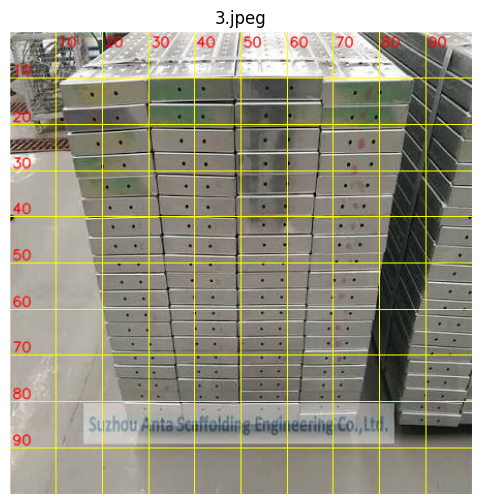

In [7]:
# ---- Cell A: upload photos and preview them with a percentage grid ----
import os, time, shutil
import numpy as np, cv2
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

if "WEIGHTS" not in globals():
    print("No trained model in this session. Upload your weights file (synth_best.pt):")
    _w = files.upload()
    WEIGHTS = next(iter(_w))
for _k, _v in {"IMGSZ": 512, "CONF": 0.5, "IOU": 0.5, "ASPECT_MAX": 6.0}.items():
    if _k not in globals():
        globals()[_k] = _v

os.makedirs("any_images", exist_ok=True)
print("Choose one or more photos")
_up = files.upload()
ANY = []
for _n in _up:
    _dst = os.path.join("any_images", _n)
    shutil.move(_n, _dst)
    ANY.append(_dst)

def grid_preview(img, title):
    g = img.copy()
    h, w = g.shape[:2]
    for p in range(10, 100, 10):
        x, y = int(w * p / 100), int(h * p / 100)
        cv2.line(g, (x, 0), (x, h), (0, 255, 255), 1)
        cv2.line(g, (0, y), (w, y), (0, 255, 255), 1)
        cv2.putText(g, str(p), (x + 2, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)
        cv2.putText(g, str(p), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)
    plt.figure(figsize=(6, 6)); plt.imshow(cv2.cvtColor(g, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title(title); plt.show()

for _p in ANY:
    _im = cv2.imread(_p)
    if _im is None:
        print("could not read", _p); continue
    grid_preview(_im, os.path.basename(_p))

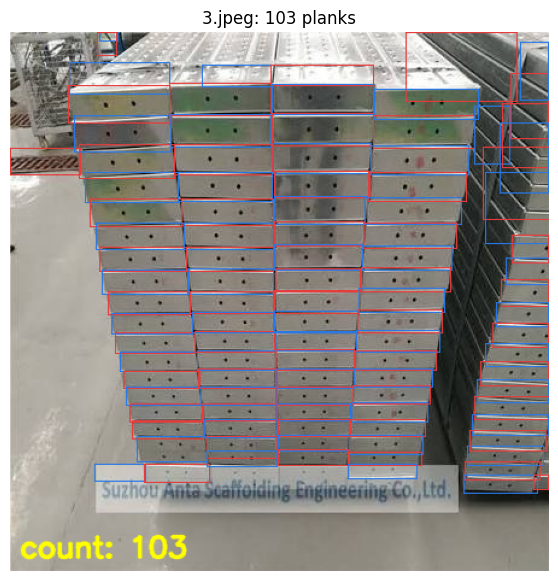

file                                      count  whole image      ms
3.jpeg                                      103          104   136.2


In [8]:
# ---- Cell B: count (re-run after changing the settings below) ----
# Which stack to count, in percent of the image: (x0, y0, x1, y1).
#   None                       -> whole image
#   (0, 40, 90, 100)           -> same box for every image
#   {"photo1.jpg": (0, 40, 90, 100), "photo2.jpg": None}  -> a box per file name
ROI_PCT = None
CONF = 0.5          # lower to find more planks, higher to remove false ones
ASPECT_MAX = 6.0    # ignore boxes wider than 6x their height (side faces)

import csv
_model = YOLO(WEIGHTS)
os.makedirs("outputs/any", exist_ok=True)
_rows = []
for _p in ANY:
    _name = os.path.basename(_p)
    _img = cv2.imread(_p)
    if _img is None:
        continue
    H, W = _img.shape[:2]
    _roi = ROI_PCT.get(_name) if isinstance(ROI_PCT, dict) else ROI_PCT
    if _roi is None:
        x0, y0, x1, y1 = 0, 0, W, H
    else:
        x0, y0, x1, y1 = int(W * _roi[0] / 100), int(H * _roi[1] / 100), int(W * _roi[2] / 100), int(H * _roi[3] / 100)
    _t = time.perf_counter()
    _r = _model.predict(_img, conf=CONF, iou=IOU, imgsz=IMGSZ, verbose=False)[0]
    _ms = (time.perf_counter() - _t) * 1000
    _keep = []
    for (cx, cy, bw, bh), b in zip(_r.boxes.xywh.tolist(), _r.boxes.xyxy.tolist()):
        if x0 <= cx <= x1 and y0 <= cy <= y1 and bw / bh <= ASPECT_MAX:
            _keep.append((b, cy))
    _keep.sort(key=lambda k: (round(k[0][0] / 40), k[1]))
    _out = _img.copy()
    if _roi is not None:
        cv2.rectangle(_out, (x0, y0), (x1, y1), (0, 200, 255), 2)
    for _i, (b, _) in enumerate(_keep, 1):
        _c = (60, 60, 230) if _i % 2 else (230, 120, 40)
        cv2.rectangle(_out, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), _c, 1)
    cv2.putText(_out, f"count: {len(_keep)}", (8, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
    cv2.imwrite(f"outputs/any/{_name}_counted.jpg", _out)
    _rows.append([_name, len(_keep), len(_r.boxes), round(_ms, 1)])
    plt.figure(figsize=(7, 7)); plt.imshow(cv2.cvtColor(_out, cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{_name}: {len(_keep)} planks"); plt.show()

with open("outputs/any/counts.csv", "w", newline="") as fh:
    _w = csv.writer(fh); _w.writerow(["file", "count", "raw_whole_image", "inference_ms"]); _w.writerows(_rows)
print(f"{'file':40s} {'count':>6s} {'whole image':>12s} {'ms':>7s}")
for _r_ in _rows:
    print(f"{_r_[0][:40]:40s} {_r_[1]:6d} {_r_[2]:12d} {_r_[3]:7.1f}")

## 9. Export for iOS (Core ML needs macOS, so ONNX is made as a fallback)

In [9]:
try:
    YOLO(WEIGHTS).export(format="coreml", nms=True, half=True, imgsz=IMGSZ)
except Exception as e:
    print("Core ML export not possible here:", str(e)[:200])
try:
    YOLO(WEIGHTS).export(format="onnx", imgsz=IMGSZ)
except Exception as e:
    print("ONNX export failed:", str(e)[:200])

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from 'runs/detect/runs/synth/weights/best.pt' with input shape (1, 3, 512, 512) BCHW and output shape(s) (1, 6, 5376) (6.2 MB)
requirements: Ultralytics requirements ['coremltools>=9.0', 'numpy>=1.14.5,<=2.3.5'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 201ms
Prepared 4 packages in 336ms
Uninstalled 1 package in 48ms
Installed 4 packages in 24ms
 + cattrs==26.2.1
 + coremltools==9.0
 - numpy==2.4.6
 + numpy==2.3.5
 + pyaml==26.7.0

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or re

/usr/local/lib/python3.13/dist-packages/coremltools/optimize/torch/palettization/fake_palettize.py:82: SyntaxWarning: invalid escape sequence '\_'
  n_bits (:obj:`int`): Number of palettization bits. There would be :math:`2^{n\_bits}` unique weights in the ``LUT``.



CoreML: starting export with coremltools 9.0...


/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Running MIL default pipeline:   0%|          | 0/95 [00:00<?, ? passes/s]/usr/local/lib/python3.13/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:273: UserWarning: Output, '847', of the source model, has been renamed to 'var_847' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
/usr/local/lib/python3.13/dist-packages/coremltools/converters/mil/mil/passes/defs/preprocess.py:273: UserWarning: Output, '849', of the source model, has been renamed to 'var_849' in the Core ML model.
  warnings.warn(msg.format(var.name, new_name))
Running MIL backend_mlprogram pipeline: 100%|███████

CoreML: starting pipeline with coremltools 9.0...
CoreML: pipeline success
CoreML: export success ✅ 19.8s, saved as 'runs/detect/runs/synth/weights/best.mlpackage' (6.1 MB)

Export complete (20.0s)
Results saved to /content/runs/detect/runs/synth/weights/best.mlpackage
Predict:         yolo predict task=detect model=runs/detect/runs/synth/weights/best.mlpackage imgsz=512 quantize=16
Validate:        yolo val task=detect model=runs/detect/runs/synth/weights/best.mlpackage imgsz=512 data=data/synthetic/dataset.yaml quantize=16
Visualize:       https://netron.app
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from 'runs/detect/runs/synth/weights/best.pt' with input shape (1, 3, 512, 512) BCHW and output shape(s) (1, 6, 5376) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Pyt

## 10. Download results (marked-up images, counts.csv, weights)

In [10]:
!cp {WEIGHTS} outputs/synth_best.pt
!zip -qr results.zip outputs
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os, zipfile
from google.colab import files

# Folder of the training run: contains best.pt, best.onnx, best.mlpackage and the training results
run_dir = os.path.dirname(os.path.dirname(os.path.abspath(WEIGHTS)))
out = "/content/scaffold_project.zip"

with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [run_dir, "/content/outputs"]:
        for root, _, fs in os.walk(folder):
            for f in fs:
                p = os.path.join(root, f)
                z.write(p, os.path.relpath(p, "/content"))
    if os.path.exists("/content/synth_data.py"):
        z.write("/content/synth_data.py", "synth_data.py")

print("zip size:", round(os.path.getsize(out) / 1e6, 1), "MB")
files.download(out)

zip size: 35.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>